# --- CELL 1: Setup and Imports ---

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import treelite
import treelite.sklearn
import tl2cgen

# Define paths
CURRENT_DIR = os.getcwd()
# Pointing to the new MPIIGaze dataset
DATASET_PATH = os.path.join(CURRENT_DIR, "datasets", "mpii_spatial_features.csv")
MODELS_DIR = os.path.join(CURRENT_DIR, "models")

os.makedirs(MODELS_DIR, exist_ok=True)
print("Environment ready.")

Environment ready.


# --- CELL 2: Load and Prepare Data ---

In [3]:
print("Loading MPIIGaze dataset...")
df = pd.read_csv(DATASET_PATH)

# Drop any rows with NaN values
df = df.dropna()

# --- NEW: OUTLIER FILTERING ---
# 1. Filter out impossible MediaPipe pupil ratios (keep between 0.1 and 0.9)
df = df[(df['student_feature_x'] > 0.1) & (df['student_feature_x'] < 0.9)]

# 2. Filter out extreme head poses (> 60 degrees) that aren't realistic for screen use
df = df[(df['head_pitch'].between(-60, 60)) & (df['head_yaw'].between(-60, 60))]

print(f"Total clean samples after filtering: {len(df)}")

X = df[['student_feature_x', 'student_feature_y', 'head_pitch', 'head_yaw', 'head_roll']]
y = df[['teacher_pitch', 'teacher_yaw']]

# Split the data (80% training, 20% testing)
X_train, X_test, y_pitch_train, y_pitch_test, y_yaw_train, y_yaw_test = train_test_split(
    X.values, y['teacher_pitch'].values, y['teacher_yaw'].values, test_size=0.2, random_state=42
)

print(f"Training on {len(X_train)} samples, testing on {len(X_test)} samples.")


Loading MPIIGaze dataset...
Total clean samples after filtering: 37593
Training on 30074 samples, testing on 7519 samples.


# --- CELL 3: Train the Gradient Boosting Models ---


In [4]:
# Gradient Boosting sequentially corrects errors, handling screen-space extremes much better than Random Forests
model_pitch = GradientBoostingRegressor(n_estimators=250, max_depth=6, learning_rate=0.05, random_state=42)
model_yaw = GradientBoostingRegressor(n_estimators=250, max_depth=6, learning_rate=0.05, random_state=42)

print("Training Pitch Model on screen-gaze data...")
model_pitch.fit(X_train, y_pitch_train)

print("Training Yaw Model on screen-gaze data...")
model_yaw.fit(X_train, y_yaw_train)

print("Training complete.")

Training Pitch Model on screen-gaze data...
Training Yaw Model on screen-gaze data...
Training complete.


# --- CELL 4: Evaluation, Visualization & Gaze Geometry Debugger ---


--- MPIIGaze Test Results ---
Yaw   - MAE: 3.00 degrees | R-squared: 0.91
Pitch - MAE: 5.05 degrees | R-squared: 0.70


C:\Users\ahmed\AppData\Local\Temp\ipykernel_22204\1549297756.py:133: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


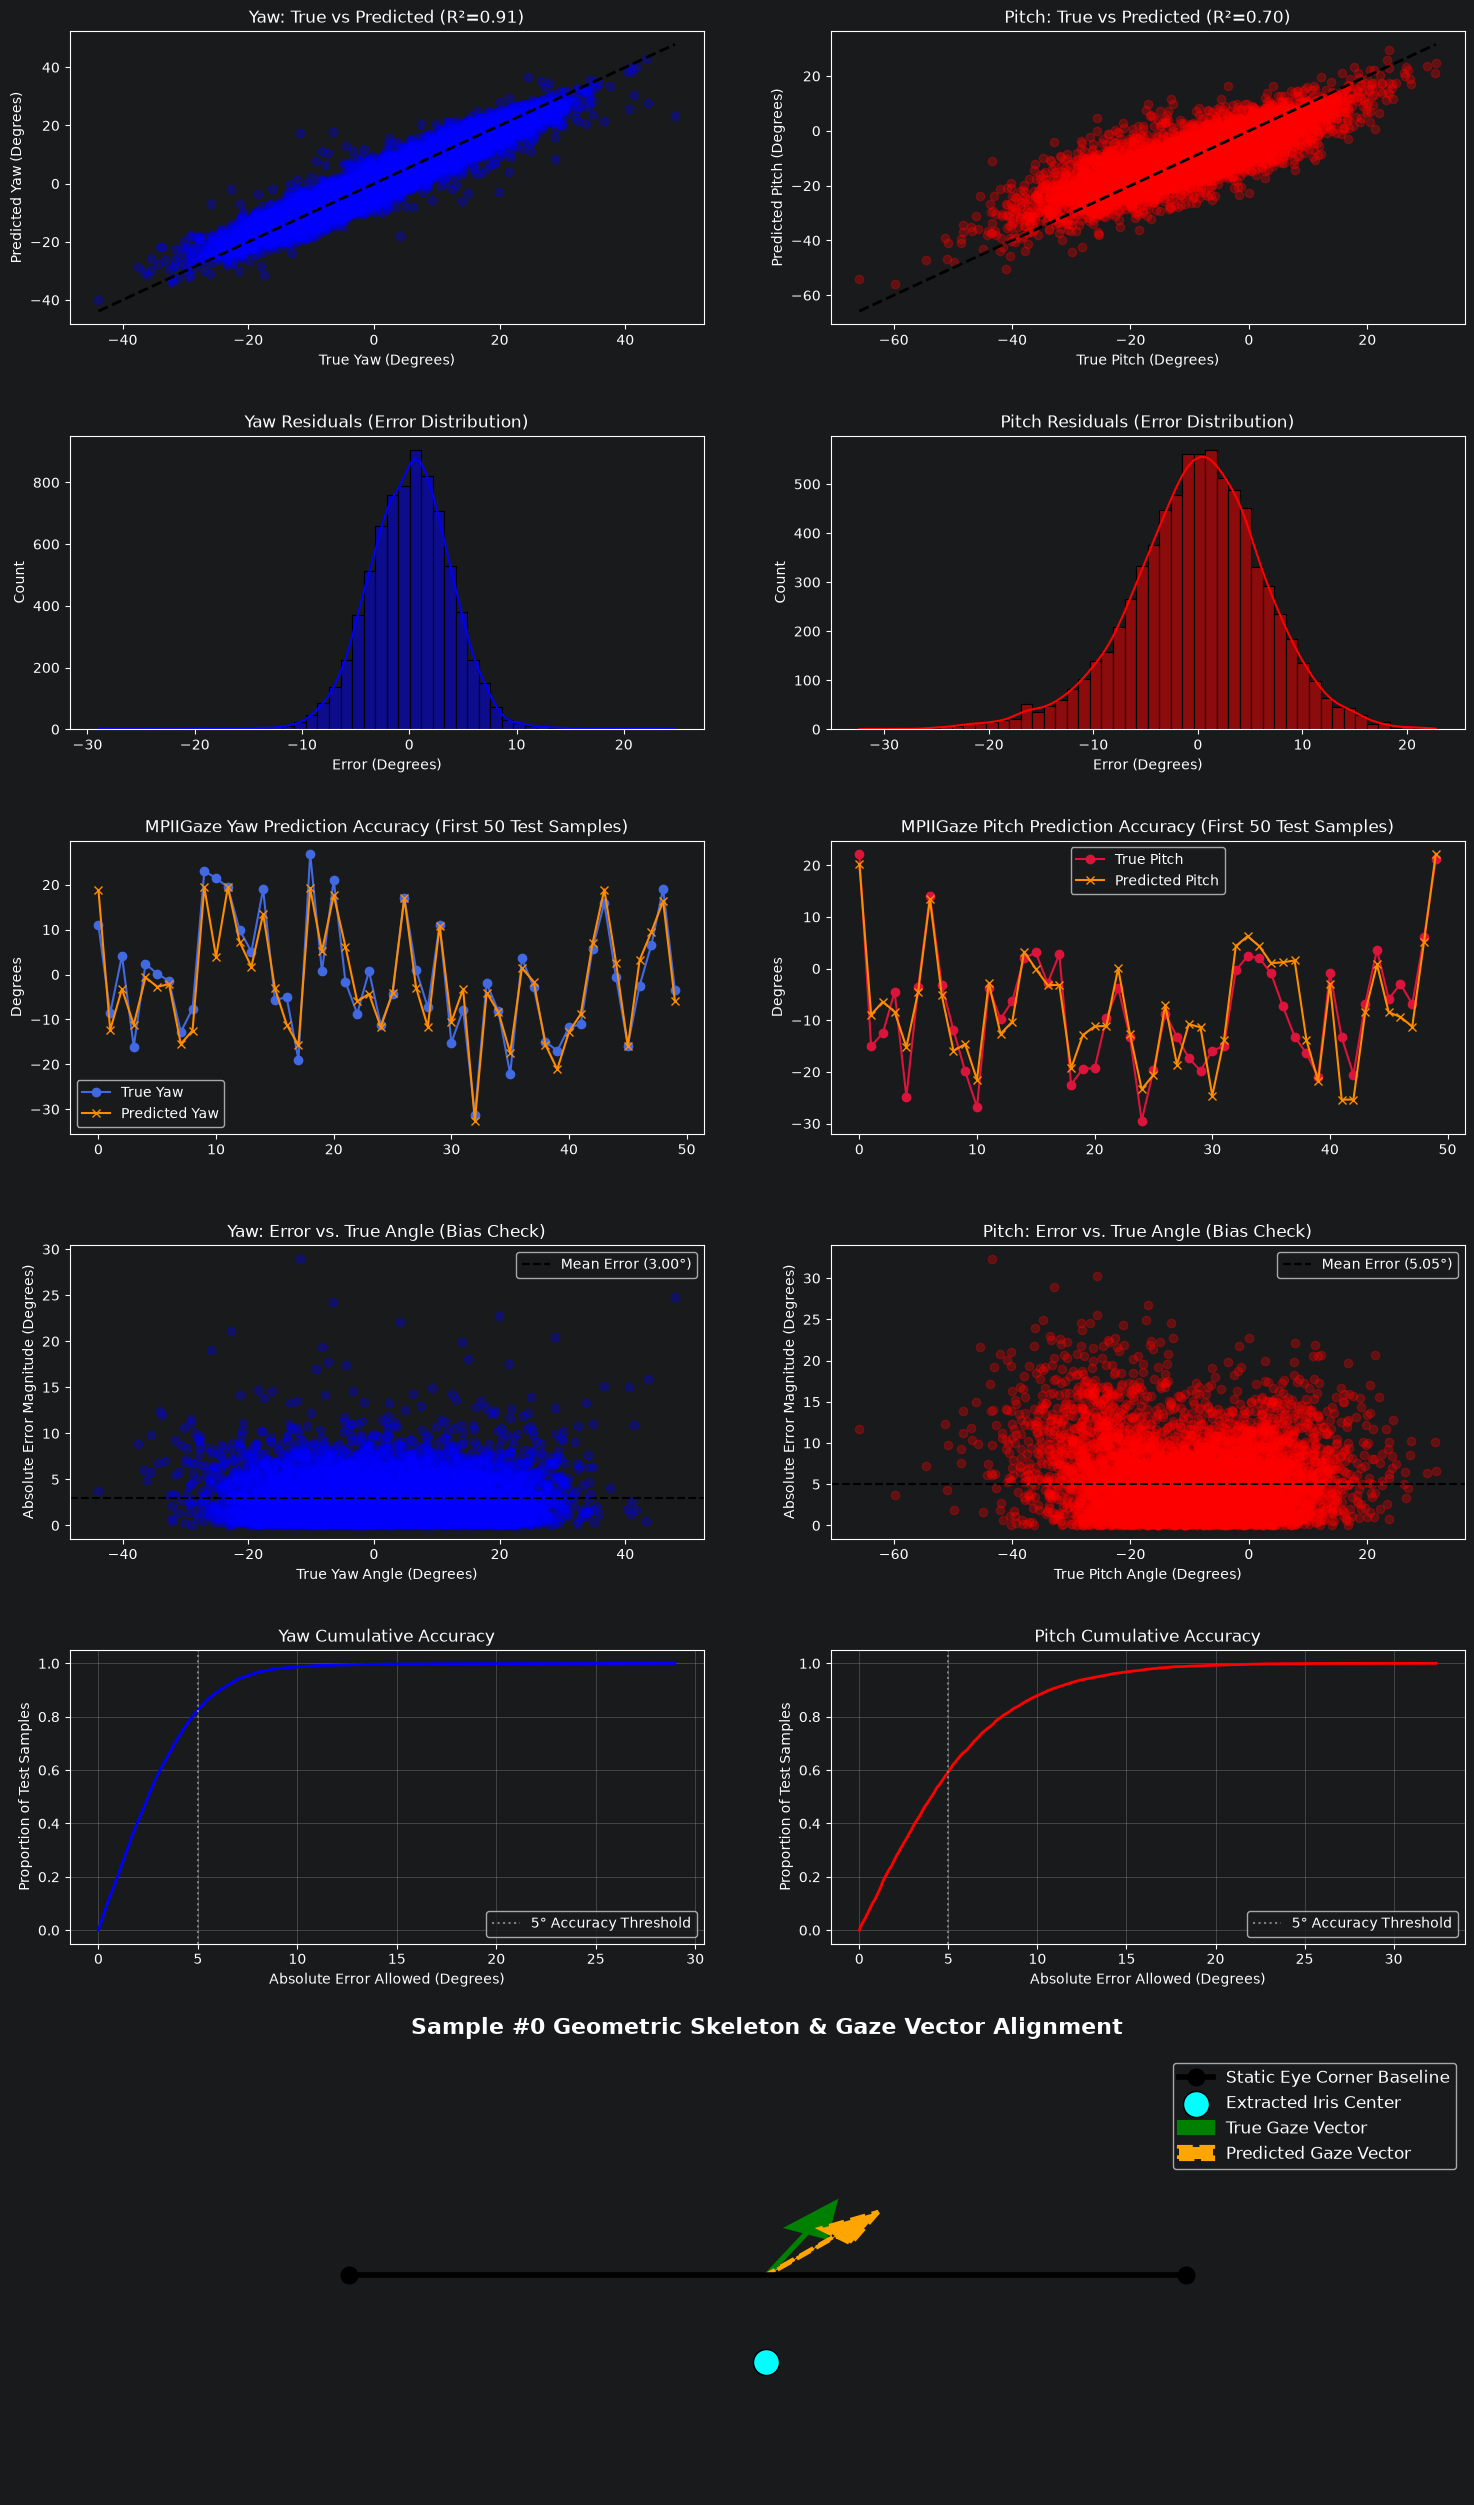

In [5]:
from sklearn.metrics import mean_absolute_error, r2_score
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np

pitch_preds = model_pitch.predict(X_test)
yaw_preds = model_yaw.predict(X_test)

pitch_mae = mean_absolute_error(y_pitch_test, pitch_preds)
yaw_mae = mean_absolute_error(y_yaw_test, yaw_preds)
pitch_r2 = r2_score(y_pitch_test, pitch_preds)
yaw_r2 = r2_score(y_yaw_test, yaw_preds)

print(f"\n--- MPIIGaze Test Results ---")
print(f"Yaw   - MAE: {yaw_mae:.2f} degrees | R-squared: {yaw_r2:.2f}")
print(f"Pitch - MAE: {pitch_mae:.2f} degrees | R-squared: {pitch_r2:.2f}")

# Switch to GridSpec to strictly control row heights and span columns for visibility
fig = plt.figure(figsize=(18, 32))
gs = GridSpec(6, 2, height_ratios=[1, 1, 1, 1, 1, 1.5], hspace=0.35)

# --- Row 1: True vs Predicted Scatter ---
ax_yaw_scatter = fig.add_subplot(gs[0, 0])
ax_yaw_scatter.scatter(y_yaw_test, yaw_preds, alpha=0.3, color='blue')
ax_yaw_scatter.plot([y_yaw_test.min(), y_yaw_test.max()], [y_yaw_test.min(), y_yaw_test.max()], 'k--', lw=2)
ax_yaw_scatter.set_xlabel('True Yaw (Degrees)')
ax_yaw_scatter.set_ylabel('Predicted Yaw (Degrees)')
ax_yaw_scatter.set_title(f'Yaw: True vs Predicted (R²={yaw_r2:.2f})')

ax_pitch_scatter = fig.add_subplot(gs[0, 1])
ax_pitch_scatter.scatter(y_pitch_test, pitch_preds, alpha=0.3, color='red')
ax_pitch_scatter.plot([y_pitch_test.min(), y_pitch_test.max()], [y_pitch_test.min(), y_pitch_test.max()], 'k--', lw=2)
ax_pitch_scatter.set_xlabel('True Pitch (Degrees)')
ax_pitch_scatter.set_ylabel('Predicted Pitch (Degrees)')
ax_pitch_scatter.set_title(f'Pitch: True vs Predicted (R²={pitch_r2:.2f})')

# --- Row 2: Residuals Distribution ---
yaw_err = y_yaw_test - yaw_preds
pitch_err = y_pitch_test - pitch_preds

ax_yaw_hist = fig.add_subplot(gs[1, 0])
sns.histplot(yaw_err, bins=50, ax=ax_yaw_hist, color='blue', kde=True)
ax_yaw_hist.set_xlabel('Error (Degrees)')
ax_yaw_hist.set_title('Yaw Residuals (Error Distribution)')

ax_pitch_hist = fig.add_subplot(gs[1, 1])
sns.histplot(pitch_err, bins=50, ax=ax_pitch_hist, color='red', kde=True)
ax_pitch_hist.set_xlabel('Error (Degrees)')
ax_pitch_hist.set_title('Pitch Residuals (Error Distribution)')

# --- Row 3: Sequence Tracking (First 50 Samples) ---
ax_yaw_seq = fig.add_subplot(gs[2, 0])
ax_yaw_seq.plot(y_yaw_test[:50], label="True Yaw", marker='o', color='royalblue')
ax_yaw_seq.plot(yaw_preds[:50], label="Predicted Yaw", marker='x', color='darkorange')
ax_yaw_seq.set_title("MPIIGaze Yaw Prediction Accuracy (First 50 Test Samples)")
ax_yaw_seq.set_ylabel("Degrees")
ax_yaw_seq.legend()

ax_pitch_seq = fig.add_subplot(gs[2, 1])
ax_pitch_seq.plot(y_pitch_test[:50], label="True Pitch", marker='o', color='crimson')
ax_pitch_seq.plot(pitch_preds[:50], label="Predicted Pitch", marker='x', color='darkorange')
ax_pitch_seq.set_title("MPIIGaze Pitch Prediction Accuracy (First 50 Test Samples)")
ax_pitch_seq.set_ylabel("Degrees")
ax_pitch_seq.legend()

# --- Row 4 (NEW): Error Magnitude vs. True Angle (Reveals Edge-Case Dropoffs) ---
ax_yaw_bias = fig.add_subplot(gs[3, 0])
ax_yaw_bias.scatter(y_yaw_test, np.abs(yaw_err), alpha=0.3, color='blue')
ax_yaw_bias.axhline(yaw_mae, color='k', linestyle='--', label=f'Mean Error ({yaw_mae:.2f}°)')
ax_yaw_bias.set_xlabel('True Yaw Angle (Degrees)')
ax_yaw_bias.set_ylabel('Absolute Error Magnitude (Degrees)')
ax_yaw_bias.set_title('Yaw: Error vs. True Angle (Bias Check)')
ax_yaw_bias.legend()

ax_pitch_bias = fig.add_subplot(gs[3, 1])
ax_pitch_bias.scatter(y_pitch_test, np.abs(pitch_err), alpha=0.3, color='red')
ax_pitch_bias.axhline(pitch_mae, color='k', linestyle='--', label=f'Mean Error ({pitch_mae:.2f}°)')
ax_pitch_bias.set_xlabel('True Pitch Angle (Degrees)')
ax_pitch_bias.set_ylabel('Absolute Error Magnitude (Degrees)')
ax_pitch_bias.set_title('Pitch: Error vs. True Angle (Bias Check)')
ax_pitch_bias.legend()

# --- Row 5 (NEW): Cumulative Error Curve (CDF) ---
ax_yaw_cdf = fig.add_subplot(gs[4, 0])
sorted_yaw_err = np.sort(np.abs(yaw_err))
cdf_yaw = np.arange(1, len(sorted_yaw_err) + 1) / len(sorted_yaw_err)
ax_yaw_cdf.plot(sorted_yaw_err, cdf_yaw, color='blue', lw=2)
ax_yaw_cdf.axvline(5, color='gray', linestyle=':', label='5° Accuracy Threshold')
ax_yaw_cdf.set_xlabel('Absolute Error Allowed (Degrees)')
ax_yaw_cdf.set_ylabel('Proportion of Test Samples')
ax_yaw_cdf.set_title('Yaw Cumulative Accuracy')
ax_yaw_cdf.grid(True, alpha=0.4)
ax_yaw_cdf.legend()

ax_pitch_cdf = fig.add_subplot(gs[4, 1])
sorted_pitch_err = np.sort(np.abs(pitch_err))
cdf_pitch = np.arange(1, len(sorted_pitch_err) + 1) / len(sorted_pitch_err)
ax_pitch_cdf.plot(sorted_pitch_err, cdf_pitch, color='red', lw=2)
ax_pitch_cdf.axvline(5, color='gray', linestyle=':', label='5° Accuracy Threshold')
ax_pitch_cdf.set_xlabel('Absolute Error Allowed (Degrees)')
ax_pitch_cdf.set_ylabel('Proportion of Test Samples')
ax_pitch_cdf.set_title('Pitch Cumulative Accuracy')
ax_pitch_cdf.grid(True, alpha=0.4)
ax_pitch_cdf.legend()

# --- Row 6 (EXPANDED): Geometric Skeleton Visualizer ---
# Merges both columns on the bottom row and increases height mapping for a massive, clear render
ax_skeleton = fig.add_subplot(gs[5, :])

sample_idx = 0
s_x = X_test.iloc[sample_idx]['student_feature_x'] if hasattr(X_test, 'iloc') else X_test[sample_idx, 0]
s_y = X_test.iloc[sample_idx]['student_feature_y'] if hasattr(X_test, 'iloc') else X_test[sample_idx, 1]
t_yaw = y_yaw_test.iloc[sample_idx] if hasattr(y_yaw_test, 'iloc') else y_yaw_test[sample_idx]
t_pitch = y_pitch_test.iloc[sample_idx] if hasattr(y_pitch_test, 'iloc') else y_pitch_test[sample_idx]
p_yaw = yaw_preds[sample_idx]
p_pitch = pitch_preds[sample_idx]

# Fixed multiplication syntax and enlarged the geometric markers
ax_skeleton.plot([0.2, 0.8], [0.5, 0.5], 'ko-', lw=4, markersize=12, label='Static Eye Corner Baseline')
ax_skeleton.scatter([0.2 + (0.6 * s_x)], [0.5 + s_y], color='cyan', s=350, edgecolors='black', zorder=5, label='Extracted Iris Center')

# Draw Gaze Vectors (Scaled up heavily for visibility)
ax_skeleton.arrow(0.5, 0.5, np.radians(t_yaw)*0.15, np.radians(t_pitch)*0.15, head_width=0.03, color='green', lw=3, label='True Gaze Vector')
ax_skeleton.arrow(0.5, 0.5, np.radians(p_yaw)*0.15, np.radians(p_pitch)*0.15, head_width=0.03, color='orange', lw=3, ls='--', label='Predicted Gaze Vector')

ax_skeleton.set_xlim(0, 1)
ax_skeleton.set_ylim(0.2, 0.8) # Tightened Y-axis bounds to eliminate empty vertical space
ax_skeleton.set_title(f"Sample #{sample_idx} Geometric Skeleton & Gaze Vector Alignment", fontsize=16, fontweight='bold', pad=15)
ax_skeleton.legend(loc='upper right', fontsize=12)
ax_skeleton.axis('off')

plt.tight_layout()
plt.show()

# --- CELL 5: Export and Compile Production DLLs ---

In [6]:
pitch_dll_path = os.path.join(MODELS_DIR, "gaze_pitch.dll")
yaw_dll_path = os.path.join(MODELS_DIR, "gaze_yaw.dll")

print("\nConverting Pitch model to Treelite format...")
treelite_pitch = treelite.sklearn.import_model(model_pitch)

print("Converting Yaw model to Treelite format...")
treelite_yaw = treelite.sklearn.import_model(model_yaw)

# parallel_comp is kept at 1 to prevent PyCharm/Jupyter memory crashes
print("Compiling Pitch DLL using tl2cgen...")
tl2cgen.export_lib(treelite_pitch, toolchain='msvc', libpath=pitch_dll_path, params={'parallel_comp': 1}, verbose=False)

print("Compiling Yaw DLL using tl2cgen...")
tl2cgen.export_lib(treelite_yaw, toolchain='msvc', libpath=yaw_dll_path, params={'parallel_comp': 1}, verbose=False)

print(f"\n[SUCCESS] Production DLLs compiled and saved to:\n - {pitch_dll_path}\n - {yaw_dll_path}")


Converting Pitch model to Treelite format...
Converting Yaw model to Treelite format...
Compiling Pitch DLL using tl2cgen...
[16:27:30] D:\a\tl2cgen\tl2cgen\src\compiler\ast\split.cc:35: Parallel compilation enabled; member trees will be divided into 1 translation units.
Compiling Yaw DLL using tl2cgen...
[16:27:57] D:\a\tl2cgen\tl2cgen\src\compiler\ast\split.cc:35: Parallel compilation enabled; member trees will be divided into 1 translation units.

[SUCCESS] Production DLLs compiled and saved to:
 - C:\Users\ahmed\Documents\grad_project\ai_pipeline\gaze_intent\models\gaze_pitch.dll
 - C:\Users\ahmed\Documents\grad_project\ai_pipeline\gaze_intent\models\gaze_yaw.dll
